In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('/kaggle/input/tp2-data-exploration/bank-full.csv', sep=';') 
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [4]:
# Remover espaços em branco das colunas
df.columns = df.columns.str.strip()

# Verificar valores "unknown" e convertê-los para NaN
for col in df.columns:
    if df[col].dtype == 'object':
        print(f"{col}: {df[col].value_counts().get('unknown', 0)} 'unknown' encontrados")
df.replace('unknown', np.nan, inplace=True)

# Preencher valores ausentes
for col in df.columns:
    if df[col].dtype == 'object':
        df[col].fillna(df[col].mode()[0], inplace=True)
    else:
        df[col].fillna(df[col].mean(), inplace=True)

# Atualizar dataset limpo
df_clean = df.copy()
print("Dimensão final do dataset limpo:", df_clean.shape)   

job: 288 'unknown' encontrados
marital: 0 'unknown' encontrados
education: 1857 'unknown' encontrados
default: 0 'unknown' encontrados
housing: 0 'unknown' encontrados
loan: 0 'unknown' encontrados
contact: 13020 'unknown' encontrados
month: 0 'unknown' encontrados
poutcome: 36959 'unknown' encontrados
y: 0 'unknown' encontrados
Dimensão final do dataset limpo: (45211, 17)


In [5]:
# Certifica-te que a coluna 'y' foi convertida para numérica
df_clean['y_num'] = df_clean['y'].map({'no': 0, 'yes': 1})

# Lista de atributos numéricos
atributos_numericos = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']

# Features e target
X = df_clean[atributos_numericos]
y_classificacao = df_clean['y_num'] 
y_regressao = df_clean['balance']  

In [6]:
# Separar treino/teste para classificação e regressão
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(X, y_classificacao, test_size=0.3, random_state=42)
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X, y_regressao, test_size=0.3, random_state=42)

# Normalização para classificação
scaler_class = StandardScaler()
X_train_class = scaler_class.fit_transform(X_train_class)
X_test_class = scaler_class.transform(X_test_class)

# Normalização para regressão
scaler_reg = StandardScaler()
X_train_reg = scaler_reg.fit_transform(X_train_reg)
X_test_reg = scaler_reg.transform(X_test_reg)

MSE: 0.09
R²: 0.1732


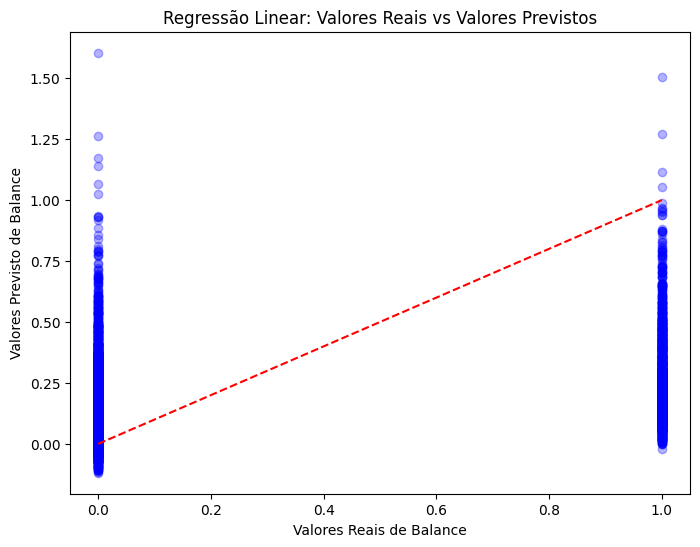

In [12]:
# Selecionar features (sem balance)
atributos_numericos = ['age', 'duration', 'campaign', 'pdays', 'previous']
X = df_clean[atributos_numericos]
y = df_clean['balance']

# Treinar modelo
model = LinearRegression()
model.fit(X_train_class, y_train_class)

# Previsão
y_pred = model.predict(X_test_class)

# Avaliação
mse = mean_squared_error(y_test_class, y_pred)
r2 = r2_score(y_test_class, y_pred)

print(f'MSE: {mse:.2f}')
print(f'R²: {r2:.4f}')

# Gráfico: Valores reais vs Valores previstos
plt.figure(figsize=(8,6))
plt.scatter(y_test_class, y_pred, alpha=0.3, color='blue')
plt.plot([y_test_class.min(), y_test_class.max()], [y_test_class.min(), y_test_class.max()], 'r--')
plt.xlabel('Valores Reais de Balance')
plt.ylabel('Valores Previsto de Balance')
plt.title('Regressão Linear: Valores Reais vs Valores Previstos')
plt.show()

Regressão Logística
Acurácia: 0.89
Relatório de Classificação:
               precision    recall  f1-score   support

           0       0.90      0.98      0.94     11966
           1       0.58      0.17      0.26      1598

    accuracy                           0.89     13564
   macro avg       0.74      0.58      0.60     13564
weighted avg       0.86      0.89      0.86     13564



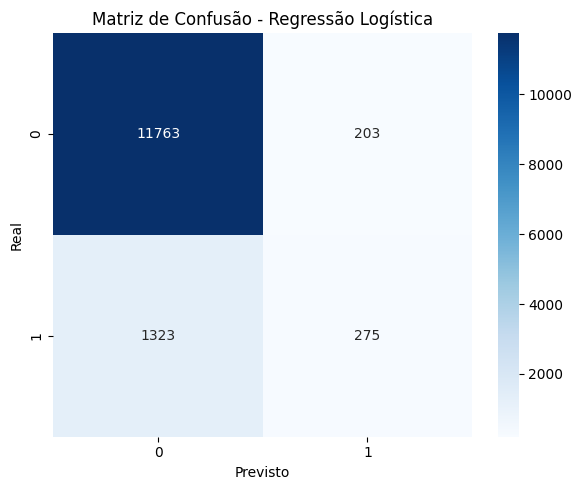

In [13]:
# Modelo de regressão logística
reg_log = LogisticRegression(max_iter=1000)
reg_log.fit(X_train_class, y_train_class)

# Previsões
y_pred_class = reg_log.predict(X_test_class)
y_pred_proba = reg_log.predict_proba(X_test_class)[:, 1]

# Avaliação
print("Regressão Logística")
print(f"Acurácia: {accuracy_score(y_test_class, y_pred_class):.2f}")
print("Relatório de Classificação:\n", classification_report(y_test_class, y_pred_class))

# Matriz de Confusão
plt.figure(figsize=(6,5))
sns.heatmap(confusion_matrix(y_test_class, y_pred_class), annot=True, fmt='d', cmap='Blues')
plt.title("Matriz de Confusão - Regressão Logística")
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

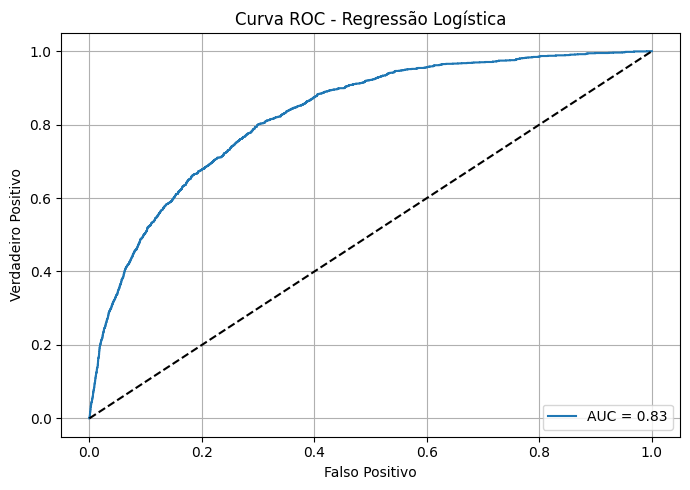

In [14]:
# Curva ROC
fpr, tpr, thresholds = roc_curve(y_test_class, y_pred_proba)
roc_auc = roc_auc_score(y_test_class, y_pred_proba)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("Falso Positivo")
plt.ylabel("Verdadeiro Positivo")
plt.title("Curva ROC - Regressão Logística")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()